# 23 · Serving under load: what users wait for, and what it costs

Notebook 06 opened up a single generation: sampling, the KV-cache, speculative decoding, batching. This notebook serves models the way an application does, through an HTTP server, many requests at a time, and measures what users and the bill see:

| question | measured here |
|---|---|
| what should we measure? | TTFT, TPOT, end-to-end latency, throughput, percentiles, with a streaming client |
| where does the time go? | prefill vs decode, as the prompt grows |
| what does prefix caching save? | the same long system prompt across requests |
| what does concurrency do? | one request slot vs four, from 1 to 8 requests in flight |
| what does the weight format cost? | the same 1.5B model in GGUF Q4_K_M, Q8_0 and FP16: speed, memory, accuracy |
| how do we serve several models? | a small gateway: fallbacks, timeouts, and a cost-aware cascade from a 3B to a 7B model |

The server is **Ollama** (llama.cpp underneath). Every lesson transfers to vLLM, SGLang, TGI or a provider's API; the end of the notebook says how.

**Sources.** *Hands-On LLM Serving* (serving metrics, batching, caching); Huyen, *AI Engineering*, ch. 9 (inference optimization) and ch. 10 (gateways, routing); Stanford CME 295, efficient inference.

## Background: the anatomy of a served request

### The metrics users feel

A streamed response has two phases, and each has its own metric:

- **TTFT (time to first token)**: from sending the request to the first token arriving. It includes queueing (waiting for a free slot), **prefill** (processing the whole prompt in one parallel pass) and network. Users feel it as "is it doing anything?".
- **TPOT (time per output token)**, also called inter-token latency: the time between tokens during **decode**. 1 / TPOT is the reading speed a single user sees. About 20–30 tokens per second already outpaces reading.
- **End-to-end latency** ≈ TTFT + TPOT × (output tokens − 1).
- **Throughput**: total output tokens per second across all users, which is what the hardware bill depends on.

Averages hide the slow requests users complain about, so serving teams set SLOs on **percentiles** (p50, p95, p99), and use **goodput**: the requests per second that *meet* the SLO.

### Prefill is compute-bound, decode is memory-bound

Prefill multiplies the whole prompt through the model at once: large matrix multiplications that keep the GPU busy (notebook 19), so it processes thousands of tokens per second. Decode produces one token per step and must read every weight from memory for it, so its speed is set by memory bandwidth, not FLOPs (notebook 06). This asymmetry drives every serving optimization:

- **batching** shares one weight read across many sequences;
- **prefix caching** skips prefill work already done;
- **quantization** shrinks the bytes read per token;
- **speculative decoding** turns several decode steps into one verification pass;
- **disaggregated serving** runs prefill and decode on different GPUs, because they stress the hardware differently (DistServe, Zhong et al., 2024; Mooncake).

### Batching: static, dynamic, continuous

- **Static batching** waits for a batch, runs it until the longest sequence finishes, and wastes slots on finished ones.
- **Continuous (in-flight) batching** (Orca, Yu et al., 2022) adds and removes sequences at every decode step, so the GPU always works on a full batch.
- **PagedAttention** (vLLM, Kwon et al., 2023) stores the KV-cache in fixed-size pages like virtual memory. It removes fragmentation and makes it possible to fit many more concurrent sequences.

llama.cpp (and so Ollama) serves a fixed number of **slots** (`OLLAMA_NUM_PARALLEL`). Each slot is one sequence in the batch, with its own share of the KV-cache, and requests beyond the slots wait in a queue. We measure both one slot and four.

### Queueing: why latency explodes near capacity

**Little's law**: requests in the system = arrival rate × time in the system. When requests arrive faster than the server completes them, the queue grows without bound, and TTFT grows with it. The useful operating point is well below saturation, where p95 latency is still acceptable. That is why capacity planning uses latency-vs-load curves, not peak throughput.

### Caching the prompt

Many requests share a long prefix: the same system prompt, the same few-shot examples, the same document. Its KV-cache can be reused instead of recomputed. vLLM calls this automatic prefix caching, SGLang uses RadixAttention (Zheng et al., 2024), and provider APIs sell it as prompt caching, with cheaper cached tokens. llama.cpp reuses the cache of a slot when the next prompt starts with the same tokens.

### Weight formats

GGUF is llama.cpp's file format. Its **k-quants** (Q4_K_M, Q5_K_M, Q6_K...) store weights in blocks with per-block scales (notebook 09), mixing precisions per tensor. Q8_0 is 8-bit; FP16/BF16 are unquantized. Fewer bits mean fewer bytes per token read, so faster decode and less memory, at some cost in quality that has to be measured on your task.

### Key references

- Yu et al. (2022), *Orca: A Distributed Serving System for Transformer-Based Generative Models* (continuous batching).
- Kwon et al. (2023), *Efficient Memory Management for Large Language Model Serving with PagedAttention* (vLLM).
- Zheng et al. (2024), *SGLang: Efficient Execution of Structured Language Model Programs* (RadixAttention).
- Zhong et al. (2024), *DistServe: Disaggregating Prefill and Decoding for Goodput-optimized LLM Serving*.
- Chen, Zaharia & Zou (2023), *FrugalGPT: How to Use Large Language Models While Reducing Cost and Improving Performance* (cascades).
- Ong et al. (2024), *RouteLLM: Learning to Route LLMs with Preference Data*.
- Little (1961), *A Proof for the Queuing Formula: L = λW*.

In [1]:
import os, sys, json, time, random, warnings
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llm_edu_suite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)                    # walk up from notebooks/<topic>/ to the repo root
sys.path.insert(0, ROOT)
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=DeprecationWarning)
random.seed(0); np.random.seed(0)

from llm_edu_suite.config import setup, get_llm, get_embeddings
info = setup(project="llm-edu-suite-23-serving")           # loads .env, picks the LangSmith project, checks that Ollama is up

provider        : ollama
chat_model      : qwen2.5:3b
judge_model     : qwen2.5:7b
embedding_model : nomic-embed-text
ollama_running  : True
langsmith       : off (add LANGSMITH_API_KEY to .env to enable)


In [2]:
warnings.filterwarnings("ignore")                       # library warnings (tqdm, Hugging Face cache) before the imports
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
import asyncio, re, shutil, socket, subprocess, httpx, datasets
from huggingface_hub.utils import logging as hf_logging; hf_logging.set_verbosity_error()
datasets.disable_progress_bars()
from llm_edu_suite.config import judge_model
from llm_edu_suite.evaluation import bootstrap_ci, paired_bootstrap_diff

BASE = os.environ.get("OLLAMA_BASE_URL", "http://localhost:11434").rstrip("/")
SMALL, BIG = info["chat_model"], judge_model()
print("Ollama", httpx.get(f"{BASE}/api/version").json()["version"], "| models:", SMALL, BIG)

async def stream_chat(client, model, messages, base=BASE, max_tokens=128, **options):
    """One streamed request. Client-side timings (what the user sees) plus the server's own counters."""
    t0 = time.perf_counter(); first = None; final = None; parts = []
    body = {"model": model, "messages": messages, "stream": True, "options": {"num_predict": max_tokens, "temperature": 0, **options}}
    async with client.stream("POST", f"{base}/api/chat", json=body) as r:
        async for line in r.aiter_lines():
            if not line:
                continue
            d = json.loads(line)
            if "error" in d:
                raise RuntimeError(d["error"])
            piece = d.get("message", {}).get("content", "")
            if piece:
                parts.append(piece)                          # the text arrives in pieces; the final chunk carries only counters
                if first is None:
                    first = time.perf_counter()
            if d.get("done"):
                final = d
    t1 = time.perf_counter()
    n = final["eval_count"]
    return {"ttft": first - t0, "e2e": t1 - t0, "tokens": n, "tpot": (t1 - first) / max(1, n - 1),
            "prompt_tokens": final.get("prompt_eval_count", 0), "cached_tokens": final.get("prompt_eval_cached_count", 0),
            "prefill_s": final.get("prompt_eval_duration", 0) / 1e9, "decode_s": final.get("eval_duration", 0) / 1e9,
            "load_s": final.get("load_duration", 0) / 1e9, "text": "".join(parts)}

async def warm(model, base=BASE, **options):
    """Load the model before timing anything. Changing num_ctx reloads it, so warm with the options you will measure with."""
    async with httpx.AsyncClient(timeout=600) as c:
        await stream_chat(c, model, [{"role": "user", "content": "hi"}], base=base, max_tokens=4, **options)
await warm(SMALL)

Ollama 0.40.15 | models: qwen2.5:3b qwen2.5:7b


## 1. Prefill vs decode as the prompt grows

One request at a time, prompts of increasing length (a block of text followed by a short question), 64 output tokens. For each, the server reports how long it spent on prefill and on decode. We disable caching between requests by changing the first line of every prompt.

prompt   110 tokens | TTFT    305 ms | prefill    3051 tok/s | decode 111.0 tok/s | TPOT   9.4 ms


prompt   338 tokens | TTFT    101 ms | prefill    3966 tok/s | decode 110.3 tok/s | TPOT   9.5 ms


prompt   621 tokens | TTFT    183 ms | prefill    3902 tok/s | decode 109.3 tok/s | TPOT   9.6 ms


prompt  1189 tokens | TTFT    341 ms | prefill    3859 tok/s | decode 107.5 tok/s | TPOT   9.7 ms


prompt  2322 tokens | TTFT    645 ms | prefill    3842 tok/s | decode 106.5 tok/s | TPOT   9.8 ms


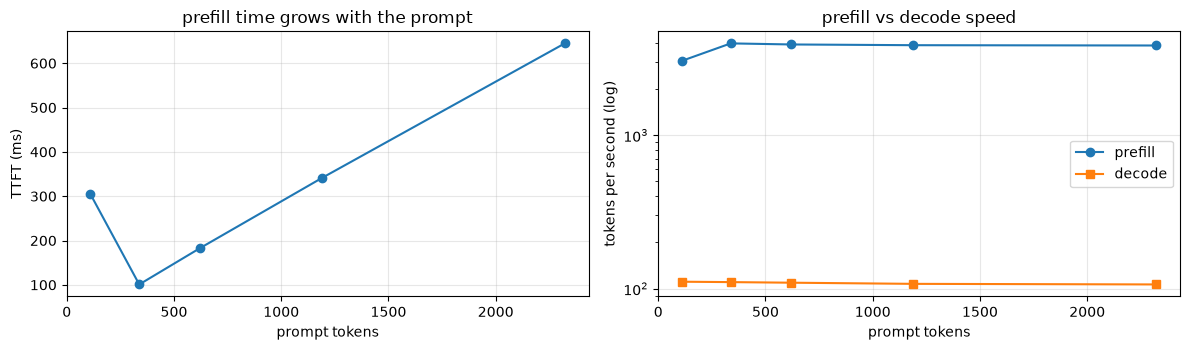

In [3]:
await warm(SMALL, num_ctx=4096)
FILLER = ("The history of trade routes shows how goods, ideas and diseases travelled together across continents. ") * 400
PREFILL = []
async with httpx.AsyncClient(timeout=600) as c:
    for words in [50, 250, 500, 1000, 2000]:
        text = " ".join(FILLER.split()[:words])
        prompt = f"Request {words}-{random.random():.6f}. {text}\n\nIn one sentence, what is this text about?"   # unique start: no cache reuse
        r = await stream_chat(c, SMALL, [{"role": "user", "content": prompt}], max_tokens=64, num_ctx=4096)
        PREFILL.append(r)
        print(f"prompt {r['prompt_tokens']:5d} tokens | TTFT {1000 * r['ttft']:6.0f} ms | prefill {r['prompt_tokens'] / r['prefill_s']:7.0f} tok/s "
              f"| decode {r['tokens'] / r['decode_s']:5.1f} tok/s | TPOT {1000 * r['tpot']:5.1f} ms")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
pt = [r["prompt_tokens"] for r in PREFILL]
ax[0].plot(pt, [1000 * r["ttft"] for r in PREFILL], "o-"); ax[0].set_xlabel("prompt tokens"); ax[0].set_ylabel("TTFT (ms)"); ax[0].set_title("prefill time grows with the prompt")
ax[1].plot(pt, [r["prompt_tokens"] / r["prefill_s"] for r in PREFILL], "o-", label="prefill")
ax[1].plot(pt, [r["tokens"] / r["decode_s"] for r in PREFILL], "s-", label="decode")
ax[1].set_yscale("log"); ax[1].set_xlabel("prompt tokens"); ax[1].set_ylabel("tokens per second (log)"); ax[1].legend(); ax[1].set_title("prefill vs decode speed")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

**What the numbers say.**

- **Prefill runs at about 3,850–3,970 tokens per second, decode at about 107–111**: the same GPU and model process the prompt **35 times faster** than they generate. That is the compute-bound vs memory-bound split in one table. Prefill handles all prompt tokens in one batch of matrix multiplications. Decode reads all 3 billion weights for every single token.
- **TTFT grows linearly with the prompt**: 101 ms at 338 tokens, 645 ms at 2,322. A long RAG context or chat history is paid in TTFT on every request unless it is cached (next section). The first row (305 ms for 110 tokens) is higher than the trend because of one-off warm-up work on the first request with this context size.
- **Decode slows only slightly as the context grows** (TPOT 9.4 → 9.8 ms): attention over 2,000 cached tokens is still small next to reading the weights. At tens of thousands of tokens, the KV-cache reads start to dominate decode too (notebook 06).

## 2. Prefix caching: a long system prompt, many questions

A 1,500-token system prompt (a policy document) and eight different user questions, sent one after the other. The server reports how many prompt tokens it could take from its cache (`prompt_eval_cached_count`) and how long prefill took.

In [4]:
POLICY = " ".join(open(os.path.join(ROOT, "data", "sample_docs", f), encoding="utf-8").read() for f in sorted(os.listdir(os.path.join(ROOT, "data", "sample_docs"))))
SYSTEM = ("You are the support assistant of an online shop. Answer only from this policy.\n\n" + POLICY + "\n\n") * 4
QS = ["How long does express shipping take?", "Can I get a refund after 40 days?", "What is the API rate limit?", "When is chat support open?",
      "How is data encrypted at rest?", "Are gift cards refundable?", "What is the minimum password length?", "Is standard shipping free?"]
CACHE = []
async with httpx.AsyncClient(timeout=600) as c:
    for q in QS:
        r = await stream_chat(c, SMALL, [{"role": "system", "content": SYSTEM}, {"role": "user", "content": q}], max_tokens=48, num_ctx=4096)
        CACHE.append(r)
        print(f"{q:40s} prompt {r['prompt_tokens']:5d} tokens, from cache {r['cached_tokens']:5d} | prefill {1000 * r['prefill_s']:6.0f} ms | TTFT {1000 * r['ttft']:6.0f} ms")
first, rest = CACHE[0], CACHE[1:]
print(f"\nfirst request TTFT {1000 * first['ttft']:.0f} ms | later requests TTFT median {1000 * np.median([r['ttft'] for r in rest]):.0f} ms "
      f"| share of prompt tokens served from cache after the first: {np.mean([r['cached_tokens'] / r['prompt_tokens'] for r in rest]):.1%}")

How long does express shipping take?     prompt  1344 tokens, from cache     5 | prefill    347 ms | TTFT    654 ms


Can I get a refund after 40 days?        prompt  1348 tokens, from cache  1332 | prefill     23 ms | TTFT     42 ms


What is the API rate limit?              prompt  1344 tokens, from cache  1332 | prefill     20 ms | TTFT     39 ms


When is chat support open?               prompt  1343 tokens, from cache  1332 | prefill     20 ms | TTFT     39 ms
How is data encrypted at rest?           prompt  1344 tokens, from cache  1332 | prefill     20 ms | TTFT     43 ms


Are gift cards refundable?               prompt  1343 tokens, from cache  1332 | prefill     20 ms | TTFT     39 ms
What is the minimum password length?     prompt  1344 tokens, from cache  1332 | prefill     21 ms | TTFT     40 ms


Is standard shipping free?               prompt  1342 tokens, from cache  1332 | prefill     19 ms | TTFT     39 ms

first request TTFT 654 ms | later requests TTFT median 39 ms | share of prompt tokens served from cache after the first: 99.1%


**What the numbers say.** The first request paid the full prefill: 347 ms for 1,344 prompt tokens, a TTFT of 654 ms. Every later request found 1,332 of its ~1,344 tokens already in the slot's KV-cache, 99.1 % of the prompt. It prefilled only the dozen tokens of the new question, in about 20 ms, and its TTFT fell to a median of **39 ms**, 17× faster.

This is the cheapest optimization in serving, and it is free if prompts are built for it: **put what is shared first** (system prompt, tools, documents, few-shot examples) and what changes last (the user's message). One changed token at the start invalidates everything after it. Provider APIs price cached input tokens at a fraction of normal ones (prompt caching), so prompt layout is also a cost decision. llama.cpp keeps one cache per slot; vLLM and SGLang share cached prefixes across requests and users.

## 3. Concurrency: one slot vs four

Sixteen requests ("write a short paragraph about the history of X", 128 tokens each) with 1, 2, 4 and 8 requests in flight at a time.

- **One slot**: the default server, which on this machine runs with one request slot.
- **Four slots**: a second, temporary Ollama server started by this notebook on a free port with `OLLAMA_NUM_PARALLEL=4`, so the default server and its settings are left untouched. We unload the models from the default server first, so the two do not compete for the 6 GB of GPU memory.

In [5]:
TOPICS = ["bread", "bicycles", "paper", "glass", "coffee", "maps", "clocks", "soap", "radio", "chess", "tea", "bridges", "ink", "salt", "silk", "ships"]
LOAD_PROMPTS = [f"Write a short paragraph about the history of {t}." for t in TOPICS]

async def load_test(model, concurrency, base=BASE, prompts=LOAD_PROMPTS, max_tokens=128):
    sem = asyncio.Semaphore(concurrency)
    async with httpx.AsyncClient(timeout=900) as c:
        async def one(p):
            async with sem:
                return await stream_chat(c, model, [{"role": "user", "content": p}], base=base, max_tokens=max_tokens)
        t0 = time.perf_counter()
        res = await asyncio.gather(*[one(p) for p in prompts])
        wall = time.perf_counter() - t0
    return {"throughput": sum(r["tokens"] for r in res) / wall, "wall": wall,
            "ttft50": np.median([r["ttft"] for r in res]), "ttft95": np.percentile([r["ttft"] for r in res], 95),
            "tpot50": np.median([r["tpot"] for r in res]), "e2e95": np.percentile([r["e2e"] for r in res], 95),
            "in_system": sum(r["e2e"] for r in res) / wall, "rate": len(res) / wall, "time_in_system": np.mean([r["e2e"] for r in res])}

def ollama_models_dir():
    """Where the running Ollama keeps its models: the desktop app logs it; otherwise OLLAMA_MODELS or the default."""
    log = os.path.join(os.environ.get("LOCALAPPDATA", ""), "Ollama", "server.log")
    if os.path.exists(log):
        found = re.findall(r"OLLAMA_MODELS:(\S+?)\s", open(log, encoding="utf-8", errors="replace").read())
        if found:
            return found[-1].replace("\\\\", "\\")
    return os.environ.get("OLLAMA_MODELS") or os.path.join(os.path.expanduser("~"), ".ollama", "models")

def start_ollama(parallel):
    with socket.socket() as s_:
        s_.bind(("127.0.0.1", 0)); port = s_.getsockname()[1]
    env = {**os.environ, "OLLAMA_HOST": f"127.0.0.1:{port}", "OLLAMA_NUM_PARALLEL": str(parallel),
           "OLLAMA_MAX_LOADED_MODELS": "1", "OLLAMA_MODELS": ollama_models_dir()}
    proc = subprocess.Popen([shutil.which("ollama"), "serve"], env=env, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    base = f"http://127.0.0.1:{port}"
    for _ in range(150):
        try:
            httpx.get(f"{base}/api/version", timeout=0.5); return proc, base
        except httpx.HTTPError:
            time.sleep(0.2)
    proc.terminate(); raise RuntimeError("the second Ollama server did not start")

def unload_all(base=BASE):
    for m in httpx.get(f"{base}/api/ps").json().get("models", []):
        httpx.post(f"{base}/api/generate", json={"model": m["name"], "keep_alive": 0}, timeout=120)

LOAD = {}
for slots in [1, 4]:
    unload_all()
    proc, base = start_ollama(slots)
    try:
        await warm(SMALL, base)
        for conc in [1, 2, 4, 8]:
            LOAD[(slots, conc)] = m = await load_test(SMALL, conc, base)
            print(f"{slots} slot(s), {conc} in flight: throughput {m['throughput']:6.1f} tok/s | TTFT p50 {1000 * m['ttft50']:6.0f} ms "
                  f"p95 {1000 * m['ttft95']:6.0f} ms | TPOT p50 {1000 * m['tpot50']:5.1f} ms | e2e p95 {m['e2e95']:5.1f} s "
                  f"| Little's law: {m['rate']:.2f} req/s x {m['time_in_system']:.2f} s = {m['rate'] * m['time_in_system']:.1f} in the system")
    finally:
        proc.terminate(); proc.wait(timeout=30)

1 slot(s), 1 in flight: throughput   83.7 tok/s | TTFT p50     39 ms p95     42 ms | TPOT p50  12.5 ms | e2e p95   1.6 s | Little's law: 0.65 req/s x 1.53 s = 1.0 in the system


1 slot(s), 2 in flight: throughput   76.1 tok/s | TTFT p50   1662 ms p95   1940 ms | TPOT p50  12.6 ms | e2e p95   3.8 s | Little's law: 0.59 req/s x 3.24 s = 1.9 in the system


1 slot(s), 4 in flight: throughput   67.1 tok/s | TTFT p50   5761 ms p95   5772 ms | TPOT p50  14.7 ms | e2e p95   7.6 s | Little's law: 0.52 req/s x 6.91 s = 3.6 in the system


1 slot(s), 8 in flight: throughput   66.8 tok/s | TTFT p50  13444 ms p95  13469 ms | TPOT p50  14.8 ms | e2e p95  15.4 s | Little's law: 0.52 req/s x 11.98 s = 6.2 in the system


4 slot(s), 1 in flight: throughput   68.1 tok/s | TTFT p50     43 ms p95     45 ms | TPOT p50  14.5 ms | e2e p95   1.9 s | Little's law: 0.53 req/s x 1.88 s = 1.0 in the system


4 slot(s), 2 in flight: throughput  124.3 tok/s | TTFT p50     42 ms p95     70 ms | TPOT p50  15.9 ms | e2e p95   2.1 s | Little's law: 0.97 req/s x 2.06 s = 2.0 in the system


4 slot(s), 4 in flight: throughput  170.8 tok/s | TTFT p50     93 ms p95     98 ms | TPOT p50  23.0 ms | e2e p95   3.0 s | Little's law: 1.33 req/s x 3.00 s = 4.0 in the system


4 slot(s), 8 in flight: throughput  172.1 tok/s | TTFT p50   2995 ms p95   3065 ms | TPOT p50  23.0 ms | e2e p95   6.0 s | Little's law: 1.34 req/s x 5.21 s = 7.0 in the system


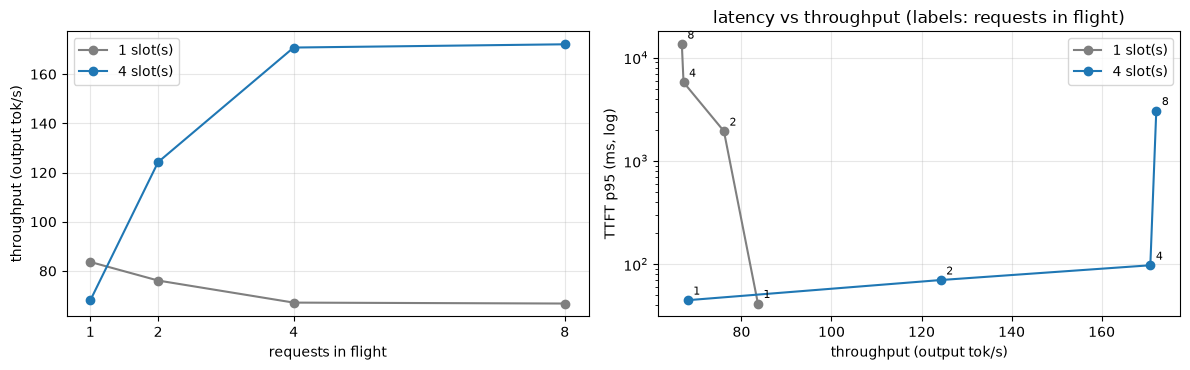

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for slots, c in [(1, "tab:gray"), (4, "tab:blue")]:
    xs = [1, 2, 4, 8]
    ax[0].plot(xs, [LOAD[(slots, k)]["throughput"] for k in xs], "o-", color=c, label=f"{slots} slot(s)")
    ax[1].plot([LOAD[(slots, k)]["throughput"] for k in xs], [1000 * LOAD[(slots, k)]["ttft95"] for k in xs], "o-", color=c, label=f"{slots} slot(s)")
    for k in xs:
        ax[1].annotate(str(k), (LOAD[(slots, k)]["throughput"], 1000 * LOAD[(slots, k)]["ttft95"]), textcoords="offset points", xytext=(4, 4), fontsize=8)
ax[0].set_xlabel("requests in flight"); ax[0].set_ylabel("throughput (output tok/s)"); ax[0].set_xticks([1, 2, 4, 8]); ax[0].legend()
ax[1].set_yscale("log"); ax[1].set_xlabel("throughput (output tok/s)"); ax[1].set_ylabel("TTFT p95 (ms, log)")
ax[1].set_title("latency vs throughput (labels: requests in flight)"); ax[1].legend()
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

**What the numbers say.**

| server | in flight | throughput (tok/s) | TTFT p50 | TPOT p50 | e2e p95 |
|---|---|---|---|---|---|
| 1 slot | 1 | 84 | 39 ms | 12.5 ms | 1.6 s |
| 1 slot | 8 | 67 | **13.4 s** | 14.8 ms | 15.4 s |
| 4 slots | 1 | 68 | 43 ms | 14.5 ms | 1.9 s |
| 4 slots | 4 | **171** | 93 ms | 23.0 ms | 3.0 s |
| 4 slots | 8 | 172 | 3.0 s | 23.0 ms | 6.0 s |

- **With one slot, concurrency only creates a queue.** Requests are served one at a time, so TTFT grows with the number waiting: 1.7 s with 2 in flight, 5.8 s with 4, 13.4 s with 8. Throughput does not improve, and it even falls slightly. This is the default server on this machine (`OLLAMA_NUM_PARALLEL=1`), and it is exactly how a single-user setup behaves when an application sends it parallel traffic.
- **Four slots batch four sequences per decode step.** Throughput rises to 171 tok/s, 2× the single slot, and TTFT stays under 100 ms up to 4 requests. The price is visible in TPOT: each user's tokens come 23 ms apart instead of 12.5 ms, because a decode step now does four sequences' work. Batching trades per-user speed for total throughput. Even a single request is slower on the 4-slot server (68 vs 84 tok/s), because the memory and kernels are set up for the batch.
- **Beyond the slots, the queue returns.** With 8 in flight on 4 slots, TTFT jumps to 3.0 s while throughput stays flat at 172 tok/s: the server is saturated.
- **Little's law holds exactly.** Arrival rate × time in the system equals the requests in flight, for example 1.33 req/s × 3.00 s = 4.0. That is how you size a deployment: from the expected request rate and the latency target, compute how many requests are in flight, then provision slots (or replicas) above that.

A server with continuous batching and PagedAttention (vLLM, SGLang, TGI) on a data-center GPU does the same thing with dozens to hundreds of sequences per step. The shape of the curves is the same.

## 4. Weight formats: Q4_K_M vs Q8_0 vs FP16

The same model, `qwen2.5:1.5b-instruct`, in three GGUF formats. For each we measure:
- the GPU memory it occupies;
- its decode speed;
- its accuracy on 200 ARC-Easy science questions (multiple choice, scored on the letter it answers);
- how often its greedy answer letter matches the FP16 model's.

In [7]:
arc = datasets.load_dataset("allenai/ai2_arc", "ARC-Easy", split="test").shuffle(seed=0).select(range(200))
def arc_prompt(r):
    opts = "\n".join(f"{l}. {t}" for l, t in zip(r["choices"]["label"], r["choices"]["text"]))
    return f"{r['question']}\n{opts}\n\nAnswer with the letter of the correct option only."
def letter(text, labels):
    m = re.search(r"\b([A-E1-5])\b", text.strip().upper())
    return m.group(1) if m and m.group(1) in labels else None

FORMATS = {"Q4_K_M": "qwen2.5:1.5b-instruct-q4_K_M", "Q8_0": "qwen2.5:1.5b-instruct-q8_0", "FP16": "qwen2.5:1.5b-instruct-fp16"}
FMT = {}
unload_all()
for fmt, tag in FORMATS.items():
    await warm(tag)
    vram = next(m["size_vram"] for m in httpx.get(f"{BASE}/api/ps").json()["models"] if m["name"].startswith(tag))
    async with httpx.AsyncClient(timeout=600) as c:
        speed = await stream_chat(c, tag, [{"role": "user", "content": LOAD_PROMPTS[0]}], max_tokens=128)
        answers = [await stream_chat(c, tag, [{"role": "user", "content": arc_prompt(r)}], max_tokens=4) for r in arc]
    picks = [letter(a["text"], r["choices"]["label"]) for a, r in zip(answers, arc)]
    FMT[fmt] = {"vram_gb": vram / 1e9, "decode": speed["tokens"] / speed["decode_s"], "picks": picks,
                "ok": np.array([p == r["answerKey"] for p, r in zip(picks, arc)], dtype=float)}
    unload_all()
for fmt, f in FMT.items():
    m, lo, hi = bootstrap_ci(f["ok"])
    agree = np.mean([a == b for a, b in zip(f["picks"], FMT["FP16"]["picks"])])
    print(f"{fmt:7s} GPU memory {f['vram_gb']:4.2f} GB | decode {f['decode']:6.1f} tok/s | ARC-Easy {m:.1%} [{lo:.1%}, {hi:.1%}] | same answer as FP16 {agree:.0%}")
for fmt in ["Q4_K_M", "Q8_0"]:
    d, lo, hi = paired_bootstrap_diff(FMT["FP16"]["ok"], FMT[fmt]["ok"])
    print(f"  {fmt} vs FP16 accuracy: {d:+.1%} [{lo:+.1%}, {hi:+.1%}]")

Q4_K_M  GPU memory 1.17 GB | decode  129.6 tok/s | ARC-Easy 89.5% [85.0%, 93.5%] | same answer as FP16 98%
Q8_0    GPU memory 1.83 GB | decode  104.5 tok/s | ARC-Easy 91.0% [87.0%, 94.5%] | same answer as FP16 100%
FP16    GPU memory 3.28 GB | decode   63.8 tok/s | ARC-Easy 91.0% [87.0%, 94.5%] | same answer as FP16 100%
  Q4_K_M vs FP16 accuracy: -1.5% [-3.5%, +0.0%]
  Q8_0 vs FP16 accuracy: +0.0% [+0.0%, +0.0%]


**What the numbers say.**

| format | GPU memory | decode | ARC-Easy (200) | same answer as FP16 |
|---|---|---|---|---|
| Q4_K_M | **1.17 GB** | **130 tok/s** | 89.5 % | 98 % |
| Q8_0 | 1.83 GB | 105 tok/s | 91.0 % | 100 % |
| FP16 | 3.28 GB | 64 tok/s | 91.0 % | — |

- **Fewer bits are faster because decode is memory-bound.** Q4_K_M reads about a third of FP16's bytes per token and decodes 2× faster. The speed-up (2.0×) is less than the 2.8× reduction in memory because dequantizing and other fixed costs remain.
- **Quality held on this task.** Q8_0 gave the same answer as FP16 on every one of the 200 questions. Q4_K_M changed 2 % of the answers and scored 1.5 points lower, an interval of [−3.5, +0.0], so a small loss at most. This matches notebook 09's measurements on our own quantization, with KL and top-1 agreement.
- **For a 1.5B model the memory saving is modest in absolute terms** (3.3 → 1.2 GB). For a 70B model the same ratio is the difference between 140 GB and about 40 GB: one GPU instead of two or more.

Default choice for local and edge serving: Q4_K_M or Q5_K_M, checked on your own evaluation set; Q8_0 when quality must match exactly. On data-center GPUs the equivalents are FP8, AWQ or GPTQ in vLLM.

## 5. A gateway: one entry point for several models

Applications rarely call one model directly. A **gateway** sits in between and gives every caller the same interface plus the cross-cutting concerns:
- routing to the right model;
- retries and fallbacks when a model fails or is slow;
- timeouts;
- budgets and cost accounting;
- logging.

LiteLLM, Portkey, OpenRouter, Kong/Envoy AI gateways and cloud API gateways do this at scale. Here is a minimal one, in a few dozen lines, so the mechanics are visible.

**Cost.** Local models have no price list, so we account in **GPU-seconds**, the time a request occupies the GPU. It is proportional to what a self-hosted model costs, and the same accounting works with per-token prices for APIs.

In [8]:
class Gateway:
    """Route a chat request to a chain of (model, timeout) pairs: try each in order and fall back on errors or timeouts."""
    def __init__(self, base=BASE):
        self.base, self.log = base, []

    async def chat(self, messages, chain, max_tokens=256):
        errors = []
        async with httpx.AsyncClient(timeout=max(t for _, t in chain)) as c:
            for model, timeout in chain:
                t0 = time.perf_counter()
                try:
                    r = await asyncio.wait_for(stream_chat(c, model, messages, base=self.base, max_tokens=max_tokens), timeout)
                    self.log.append({"model": model, "ok": True, "gpu_s": r["prefill_s"] + r["decode_s"], "wall_s": time.perf_counter() - t0})
                    return {"model": model, "text": r["text"], "errors": errors, "gpu_s": r["prefill_s"] + r["decode_s"]}
                except Exception as e:                         # model missing, server error, timeout: try the next one
                    errors.append(f"{model}: {type(e).__name__}: {str(e)[:60]}")
                    self.log.append({"model": model, "ok": False, "gpu_s": 0.0, "wall_s": time.perf_counter() - t0})
        raise RuntimeError(f"all models failed: {errors}")

gw = Gateway()
q = [{"role": "user", "content": "In one sentence: why is the sky blue?"}]
for chain in [[("no-such-model:latest", 60), (SMALL, 60)],      # a model that does not exist: fall back
              [(BIG, 0.5), (SMALL, 60)],                       # a model too slow for its timeout (it must load first): fall back
              [(SMALL, 60)]]:                                  # the normal case
    out = await gw.chat(q, chain, max_tokens=60)
    print(f"chain {chain} -> answered by {out['model']} | errors before: {out['errors']}\n   {out['text'][:120]}")
print("gateway log:", [(e["model"], e["ok"], round(e["wall_s"], 2)) for e in gw.log])

chain [('no-such-model:latest', 60), ('qwen2.5:3b', 60)] -> answered by qwen2.5:3b | errors before: ["no-such-model:latest: RuntimeError: model 'no-such-model:latest' not found"]
   The sky appears blue because molecules in the Earth's atmosphere scatter sunlight more efficiently in the blue part of t


chain [('qwen2.5:7b', 0.5), ('qwen2.5:3b', 60)] -> answered by qwen2.5:3b | errors before: ['qwen2.5:7b: TimeoutError: ']
   The sky appears blue because molecules in the Earth's atmosphere scatter sunlight more efficiently in the blue part of t


chain [('qwen2.5:3b', 60)] -> answered by qwen2.5:3b | errors before: []
   The sky appears blue because molecules in the Earth's atmosphere scatter sunlight more efficiently in the blue part of t
gateway log: [('no-such-model:latest', False, 0.27), ('qwen2.5:3b', True, 4.04), ('qwen2.5:7b', False, 0.52), ('qwen2.5:3b', True, 3.78), ('qwen2.5:3b', True, 0.58)]


**What the numbers say.** All three chains returned an answer:

- The missing model failed in 0.27 s with a clear error and the gateway fell back to `qwen2.5:3b`, which answered in 4.0 s (including loading it into memory).
- The 7B model, with a 0.5 s budget, timed out while loading, and the gateway fell back again.
- The normal call took 0.58 s.

The log records every attempt, failures included. That log is what you need to see that a model is down, or that a timeout is too tight, before users notice. A production gateway adds:
- retries with backoff for transient errors;
- circuit breakers, which stop sending traffic to a failing model for a while;
- per-key rate limits and budgets;
- caching of identical requests;
- a single OpenAI-compatible API in front of every provider (LiteLLM's proxy, Portkey, OpenRouter, or a cloud AI gateway).

### Cost-aware routing: a cascade from 3B to 7B

The expensive model is needed only for the questions the cheap one gets wrong, but you do not know in advance which ones those are. A **cascade** (FrugalGPT) asks the cheap model first and escalates only when a cheap signal says it is unsure. Our signal is **agreement**: the 3B model answers twice, once greedily and once sampled at temperature 0.7, and the question goes to the 7B model only if the two final numbers differ.

We compare it with always-3B and always-7B on the 80 GSM8K problems of notebook 20, on accuracy and GPU-seconds.

escalated to qwen2.5:7b: 16% of problems | 3B wrong among escalated: 77%, among kept: 6%
always 3B          accuracy 82.5% [73.8%, 90.0%] | GPU-seconds per problem  3.67 (37% of always-7B)
always 7B          accuracy 78.8% [70.0%, 87.5%] | GPU-seconds per problem  9.85 (100% of always-7B)
cascade 3B -> 7B   accuracy 85.0% [77.5%, 92.5%] | GPU-seconds per problem  8.70 (88% of always-7B)
oracle router (perfect choice per problem): 87.5%
cascade vs always-7B accuracy: +6.2% [+0.0%, +13.8%]


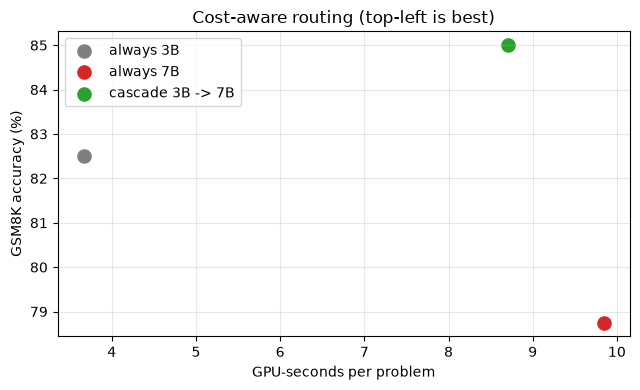

In [9]:
N_PROB = 80
gsm = datasets.load_dataset("openai/gsm8k", "main", split="test").shuffle(seed=0).select(range(N_PROB))
GOLD = [float(a.split("####")[-1].replace(",", "").strip()) for a in gsm["answer"]]
COT = "Solve the problem step by step, then give the final answer as a number on the last line."
def final_number(text):
    m = re.findall(r"-?\d+(?:\.\d+)?", text.replace(",", "").replace("$", ""))
    return float(m[-1]) if m else None

async def solve_all(model, temperature=0.0, concurrency=1):
    sem = asyncio.Semaphore(concurrency)
    async with httpx.AsyncClient(timeout=900) as c:
        async def one(q):
            async with sem:
                return await stream_chat(c, model, [{"role": "system", "content": COT}, {"role": "user", "content": q}],
                                         max_tokens=400, temperature=temperature, seed=1)
        return await asyncio.gather(*[one(q) for q in gsm["question"]])

small_greedy = await solve_all(SMALL)
small_sampled = await solve_all(SMALL, temperature=0.7)
big = await solve_all(BIG)
gpu = lambda r: r["prefill_s"] + r["decode_s"]
ok = lambda r, g: (final_number(r["text"]) is not None) and abs(final_number(r["text"]) - g) < 1e-6

escalate = np.array([final_number(a["text"]) != final_number(b["text"]) for a, b in zip(small_greedy, small_sampled)])
STRAT = {
    "always 3B": (np.array([ok(r, g) for r, g in zip(small_greedy, GOLD)], dtype=float), np.array([gpu(r) for r in small_greedy])),
    "always 7B": (np.array([ok(r, g) for r, g in zip(big, GOLD)], dtype=float), np.array([gpu(r) for r in big])),
    "cascade 3B -> 7B": (np.array([ok(b, g) if e else ok(a, g) for a, b, e, g in zip(small_greedy, big, escalate, GOLD)], dtype=float),
                         np.array([gpu(a) + gpu(s) + (gpu(b) if e else 0) for a, s, b, e in zip(small_greedy, small_sampled, big, escalate)])),
}
oracle = np.array([ok(a, g) or ok(b, g) for a, b, g in zip(small_greedy, big, GOLD)], dtype=float)
print(f"escalated to {BIG}: {escalate.mean():.0%} of problems | 3B wrong among escalated: {1 - STRAT['always 3B'][0][escalate].mean():.0%}, "
      f"among kept: {1 - STRAT['always 3B'][0][~escalate].mean():.0%}")
for name, (acc, cost) in STRAT.items():
    m, lo, hi = bootstrap_ci(acc)
    print(f"{name:18s} accuracy {m:.1%} [{lo:.1%}, {hi:.1%}] | GPU-seconds per problem {cost.mean():5.2f} ({cost.mean() / STRAT['always 7B'][1].mean():.0%} of always-7B)")
print(f"oracle router (perfect choice per problem): {oracle.mean():.1%}")
d, lo, hi = paired_bootstrap_diff(STRAT["always 7B"][0], STRAT["cascade 3B -> 7B"][0])
print(f"cascade vs always-7B accuracy: {d:+.1%} [{lo:+.1%}, {hi:+.1%}]")

fig, ax = plt.subplots(figsize=(6.5, 4))
for (name, (acc, cost)), c in zip(STRAT.items(), ["tab:gray", "tab:red", "tab:green"]):
    ax.scatter(cost.mean(), 100 * acc.mean(), s=90, color=c, label=name)
ax.set_xlabel("GPU-seconds per problem"); ax.set_ylabel("GSM8K accuracy (%)"); ax.grid(alpha=.3); ax.legend()
ax.set_title("Cost-aware routing (top-left is best)")
plt.tight_layout(); plt.show()

**What the numbers say.**

| strategy | GSM8K accuracy (80) | GPU-seconds per problem |
|---|---|---|
| always 3B | 82.5 % | 3.67 |
| always 7B | 78.8 % | 9.85 |
| cascade 3B → 7B | **85.0 %** | 8.70 |
| oracle router (best per problem) | 87.5 % | — |

- **The escalation signal works.** The two 3B answers disagreed on 16 % of the problems. On those, the 3B model was wrong 77 % of the time; on the 84 % where they agreed, only 6 %. Disagreement is a cheap, label-free estimate of uncertainty, the same idea as self-consistency in notebook 20.
- **The cascade was the most accurate**: 85.0 %, 6.2 points above always-7B (interval [+0.0, +13.8]) and 2.5 above always-3B. It gets close to the 87.5 % of a perfect router.
- **It was not the cheapest.** The second 3B sample, needed for the agreement check, doubles the cost of every problem, so the cascade used 88 % of always-7B's GPU time. Cheaper uncertainty signals would cut that: the token log-probabilities of a single answer, a small trained router (RouteLLM), or a verifier.
- **The bigger model was not better here.** The 7B model scored *below* the 3B (78.8 % vs 82.5 %), though their intervals overlap widely ([70.0, 87.5] and [73.8, 90.0]), so 80 problems cannot tell them apart. Its scale does not guarantee a gain on this task with this prompt and token budget. Like the judge in notebook 22, the expensive option has to be measured, not assumed.

Routing pays most when the price gap between models is large: a local or small model in front of a frontier API, where the large model can cost 10–50× more per token.

## Results

| question | measured (Ollama 0.40, RTX 3060 Laptop 6 GB) | lesson |
|---|---|---|
| prefill vs decode | prefill ~3,900 tok/s, decode ~110 tok/s (35×); TTFT 101 → 645 ms from 338 to 2,322 prompt tokens | long prompts cost TTFT; decode is memory-bound |
| prefix caching | 99.1 % of the prompt from cache after the first request; TTFT 654 → 39 ms | put the shared part of the prompt first |
| concurrency, 1 slot | throughput flat (84 → 67 tok/s); TTFT 39 ms → 13.4 s with 8 in flight | without batching, concurrency is a queue |
| concurrency, 4 slots | 171 tok/s (2×) with TTFT < 100 ms up to 4 in flight; TPOT 12.5 → 23 ms | batching trades per-user speed for throughput |
| Little's law | in flight = rate × time in system, to the decimal | size deployments from rate and latency targets |
| weight formats (1.5B) | Q4_K_M: 1.17 GB, 130 tok/s, 89.5 %; Q8_0: 1.83 GB, 105 tok/s, 91.0 %; FP16: 3.28 GB, 64 tok/s, 91.0 % | 4-bit doubles speed for ≤ 1.5 points on this task |
| gateway | missing model and timeout both fell back; every attempt logged | resilience belongs in one place |
| cost-aware cascade | 85.0 % vs 82.5 % (3B) and 78.8 % (7B), at 88 % of the 7B's GPU time | escalation signals work; their own cost matters |

What this establishes: serving performance is a set of measurable trade-offs. Most of the wins come from configuration: slots, cache-friendly prompts, weight format and routing. All of it is measured with a few hundred lines of client code.

## In production

**Choosing a server.**
- Use llama.cpp or Ollama for local, edge and single-user setups, CPUs, Apple Silicon and small GPUs; set `OLLAMA_NUM_PARALLEL` and the context size for your traffic.
- Use vLLM, SGLang or TGI on data-center GPUs for multi-user traffic: continuous batching, PagedAttention, prefix caching across users, FP8 and AWQ weights, speculative decoding, tensor parallelism. TensorRT-LLM gives NVIDIA's highest throughput at the cost of build complexity.
- All of them expose an OpenAI-compatible API, so the client code and the gateway do not change.

**SLOs and capacity.**
- Set targets on TTFT p95 and TPOT p95 (for example TTFT < 1 s, TPOT < 50 ms) and measure goodput against them.
- Load-test with realistic prompt and output lengths and arrival patterns (`vllm bench`, `genai-perf`, Locust, k6).
- Keep utilization below the knee of the latency curve, and autoscale on queue length or KV-cache usage, not CPU.

**Cost.**
- Cache-friendly prompts first.
- Then quantized weights validated on your evaluation set.
- Then routing or cascades between model sizes, with a cheap uncertainty signal.
- Batch offline work (notebook 13) on separate capacity or batch APIs.

**What to monitor.**
- TTFT, TPOT and end-to-end percentiles per model and route.
- Queue length and time in queue.
- Tokens per second.
- Cache hit rate, KV-cache utilization and preemptions.
- Error and timeout rates per backend, and fallback counts.
- GPU memory and utilization.
- Cost per request and per user.

**Failure modes.**
- An application sending parallel traffic to a single-slot server.
- A prompt layout that defeats the cache (a timestamp at the top).
- Context sizes that silently reload the model.
- Over-quantized models that pass a smoke test and fail on your edge cases.
- Timeouts shorter than a cold model load.
- Fallbacks that hide a dead primary.
- Routers whose signal costs more than it saves.

**Next:** notebooks 10–14 put these models to work in applications; notebook 15 adds observability to everything served here.